# Présentation des prédictions du modèle

Dataset : Amendements, n_train = 600, n_valid = 300 and n_test = 300.  
Modèle choisi : Modèle B (Hornet).    

In [ ]:
import polars as pl
import polars.selectors as cs
import matplotlib.pyplot as plt
import numpy as np

pred_hornet = pl.read_csv("data/predictions_hornet_model.csv")
amendements = pl.read_csv("data/amendements.csv")

pred_hornet = pred_hornet.rename({"text": "expose_sommaire"})

## Deux datasets

On compile les résultats pour deux datasets :  
- L'un est la prédiction sur le clean_dataset (amendements uniques)
- L'autre étend la précédente prédiction à tous les amendements de la XVIIème législature, à l'exception des amendements dont l'exposé sommaire est null ou fait +1024 tokens (amendements avec duplicats)

### 1) Clean_dataset (amendements uniques)

In [2]:
#Adding metadata from amendements dataset to hornet predictions 
pred_dataset_uni = amendements.join(pred_hornet, on="uid", how="inner", coalesce=True)

### 2) Dataset duplicats (toute la XVIIème législature, sauf les amendements dont l'exposé sommaire est null ou fait +1024 tokens)

In [3]:
#Removing amendements with no expose_sommaire 
#(we lose few information: only 6 have a dispositif, the others 22,120's dispositif is null)
amendements = amendements.filter(~pl.col("expose_sommaire").is_null())

#Building the extended dataset
pred_dataset_ext = amendements.join(pred_hornet, on="expose_sommaire", how="left", coalesce=True)
pred_dataset_ext = pred_dataset_ext.drop("uid_right")

#Printing basic statistics
print(f"There are {pred_dataset_ext.filter(pl.col("dataset").is_null()).shape[0]} values of +1024 tokens."
      " They are removed from the dataset.")

#Removing rows with null labels (because they have +1024 tokens) 
pred_dataset_ext = pred_dataset_ext.filter(~pl.col("expose_sommaire").is_null())

There are 969 values of +1024 tokens. They are removed from the dataset.


## RQ1: Combien d'amendements sont dits sourcés parmi les amendements déposés sous la XVIIème législature ?

In [4]:
"""
This function takes a dataframe of predictions as input
and returns a dataframe with frequency counts and %. 
"""

def freq_count(pred_dataset):

    #count source and non_source items among predictions and manual labels
    freqs = {"total_source": (pred_dataset.filter(~pl.col("prediction")
                                                  .is_null()).filter(pl.col("prediction") == "source")
                                                  .shape[0]),
            "total_non-source": (pred_dataset.filter(~pl.col("prediction")
                                                     .is_null()).filter(pl.col("prediction") == "non-source")
                                                     .shape[0])}
    df_freqs = pl.DataFrame(freqs)

    df_freqs = df_freqs.with_columns((pl.col("total_source")+pl.col("total_non-source")).alias("total_not_null"))

    df_freqs = df_freqs.with_columns((pl.col("total_source")/pl.col("total_not_null")).alias("%_source"))
    df_freqs = df_freqs.with_columns((pl.col("total_non-source")/pl.col("total_not_null")).alias("%_non-source"))

    return df_freqs

In [5]:
"""
This function takes the output of freq_count() as input
and outputs a pie chart representing the repartition of source and non-source amendements 
    out of the total amount of (non null and -1024 tokens) amendements. 
"""

def freq_plot(df_freqs):
    df = df_freqs.select("%_source", "%_non-source")
    df = df.transpose(include_header = True, header_name="stat", column_names=["percentage"])

    couleurs_source = {"%_source": "#3C6E71", "%_non-source": '#483C46'}
    couleurs = [couleurs_source.get(n, "gray") for n in df["stat"]]

    fig, ax = plt.subplots(dpi=150)
    wedges, texts, autotexts = ax.pie(df["percentage"], 
            autopct = '%1.1f%%',
            pctdistance=0.65,
            colors=couleurs, 
            wedgeprops = {"edgecolor" : "white",
                      'linewidth': 1})

    for at in autotexts:
        at.set_color('white')
        at.set_fontweight('bold')

    ax.legend(labels=df["stat"],
              prop={"family": "Times New Roman", "size": 13}, 
              loc="center right", 
              bbox_to_anchor=(0.08, 0.5), 
              edgecolor="none", 
              borderpad=0)

### Unique dataset

In [6]:
freq_count(pred_hornet)

total_source,total_non-source,total_not_null,%_source,%_non-source
i64,i64,i64,f64,f64
5069,60319,65388,0.077522,0.922478


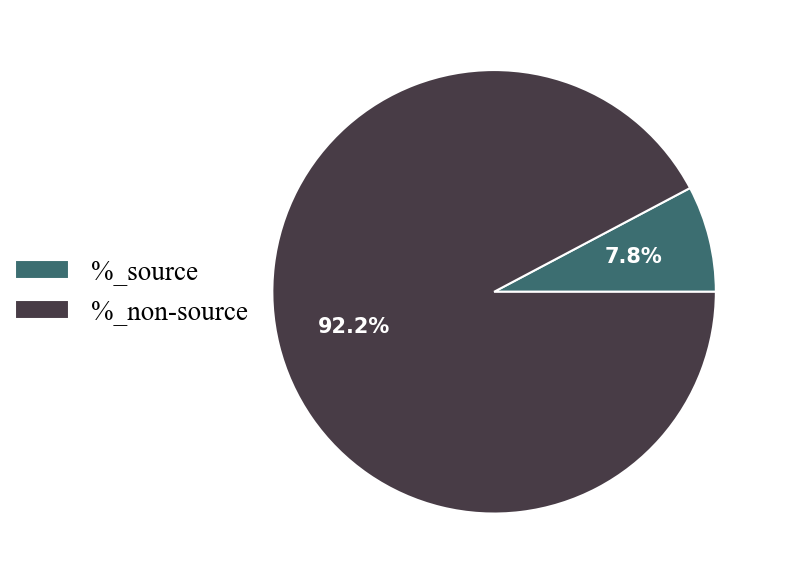

In [7]:
freq_plot(freq_count(pred_dataset_uni))

### Duplicate dataset

In [8]:
freq_count(pred_dataset_ext)

total_source,total_non-source,total_not_null,%_source,%_non-source
i64,i64,i64,f64,f64
6584,93545,100129,0.065755,0.934245


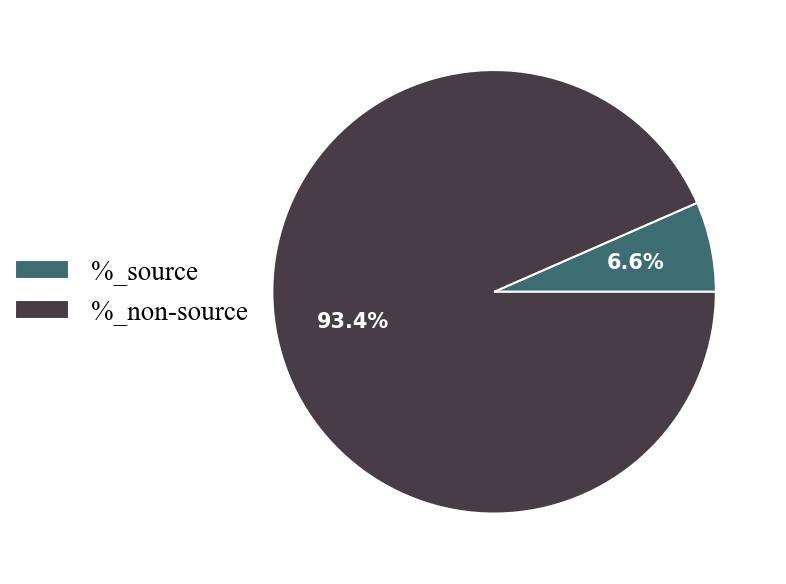

In [9]:
freq_plot(freq_count(pred_dataset_ext))

## RQ2: Quel parti politique source-t-il le plus ses amendements ?

In [ ]:
"""
This function takes a dataframe of predictions as input
and returns a dataframe with frequency counts and % of sourced amendments per party. 
"""

def pol_party(pred_dataset):

    #fetch the sourced predictions by party
    stats_party = pred_dataset.filter(
        ~pl.col("prediction").is_null()).filter(
            pl.col("prediction") == "source")["auteur_groupe_politique_ref"].value_counts().sort(
                by="auteur_groupe_politique_ref", nulls_last=True)
    stats_party = stats_party.with_columns(pl.col("count").fill_null(strategy="zero"))
    stats_party = stats_party.rename({"count": "total_source"})

    #fetch total amendements over the period
    df = pred_dataset["auteur_groupe_politique_ref"].value_counts()
    stats_party = stats_party.join(df, on="auteur_groupe_politique_ref", how="left")
    stats_party = stats_party.with_columns(pl.col("count").fill_null(strategy="zero"))
    stats_party = stats_party.rename({"count": "total_amendements"})

    #add legible names
    df = pl.read_csv("data/AN_metadata/*.csv", separator=";")
    df = df.rename({"uid[1]": "auteur_groupe_politique_ref", 
                    "libelle[1]": "nom", 
                    "libelleAbrege[1]": "nom_abrev"})
    stats_party = stats_party.join(df.select(["auteur_groupe_politique_ref", "nom", "nom_abrev"]), 
                                   on="auteur_groupe_politique_ref", how="left", nulls_equal=True)

    #remove duplicate political groups (same abreviation, different full name)
    stats_party = stats_party.group_by("nom_abrev", maintain_order=True).agg(
        cs.string().first(),
        cs.numeric().sum())

    #compute % of sourced amendements
    stats_party = stats_party.with_columns(
        ((pl.col("total_source")/pl.col("total_amendements"))*100).alias("%_source"))

    return stats_party

In [11]:
"""
This function takes the output of pol_party(), a y_axis ("total_amendements" if the goal is to plot the 
total volume of amendments, or "%_source" if the goal is to plot %) and a title as input
and outputs a bar chart representing what percentage of amendments per party have been sourced 
(excluding null amendments and amendments of more than 1024 tokens). 
"""

def plot_pol_party(stats_party, y_axis, title):
    
    table = stats_party.filter(~pl.col("auteur_groupe_politique_ref").is_null())
    table = table.sort(by=y_axis, descending = True)

    width=0.98
    couleurs_groupes_politiques = {
        "RN":      "#1F4E8C",  
        "EPR":     "#F2C14E",  
        "LFI-NFP": "#C8385A",  
        "SOC":     "#F08A93",  
        "DR":      "#3A7CC4",  
        "EcoS":    "#4CA86A",  
        "Dem":     "#F29E4C",  
        "HOR":     "#8FC1E3",  
        "LIOT":    "#9AA0A6",  
        "GDR":     "#B3262E",  
        "UDR":     "#2B2D33",  
        "NI":      "#D3D6DA",  
        }   
    couleurs = [couleurs_groupes_politiques.get(n, "gray") for n in table["nom_abrev"]]

    fig, axbar=plt.subplots(figsize=(8, 6), dpi=150)
    bars = axbar.bar(table["nom_abrev"], table[y_axis], 
                width=width,
                color=couleurs,
                edgecolor="white",
                linewidth=1.5)
    
    axbar.margins(0.01, 0.01)
    axbar.set_title(title,  
                family="Times New Roman", 
                fontsize=12)
    
    for tick in axbar.get_xticklabels():
        tick.set_fontname("Times New Roman")
    for tick in axbar.get_yticklabels():
        tick.set_fontname("Times New Roman")

    if "%" in y_axis:
        axbar.bar_label(bars, fmt='%.2f%%', padding=2, fontsize=8, fontfamily="Times New Roman")
    else: 
        axbar.bar_label(bars, padding=2, fontsize=8, fontfamily="Times New Roman")

    axbar.spines[['right', 'top']].set_visible(False)

### Unique dataset

In [12]:
pol_party(pred_dataset_uni).sort(by="%_source", descending=True)

nom_abrev,auteur_groupe_politique_ref,nom,total_source,total_amendements,%_source
str,str,str,u32,u32,f64
"""NI""","""PO840056""","""Non inscrit""",106,543,19.521179
"""LIOT""","""PO845485""","""Libertés, Indépendants, Outre-…",499,3280,15.213415
"""HOR""","""PO845470""","""Horizons & Indépendants""",331,2440,13.565574
"""Dem""","""PO845454""","""Les Démocrates""",336,2603,12.908183
"""EPR""","""PO845407""","""Ensemble pour la République""",933,7335,12.719836
…,…,…,…,…,…
"""GDR""","""PO845514""","""Gauche Démocrate et Républicai…",270,2982,9.054326
"""LFI-NFP""","""PO845413""","""La France insoumise - Nouveau …",512,10449,4.89999
"""DR""","""PO845425""","""Droite Républicaine""",303,8726,3.472381


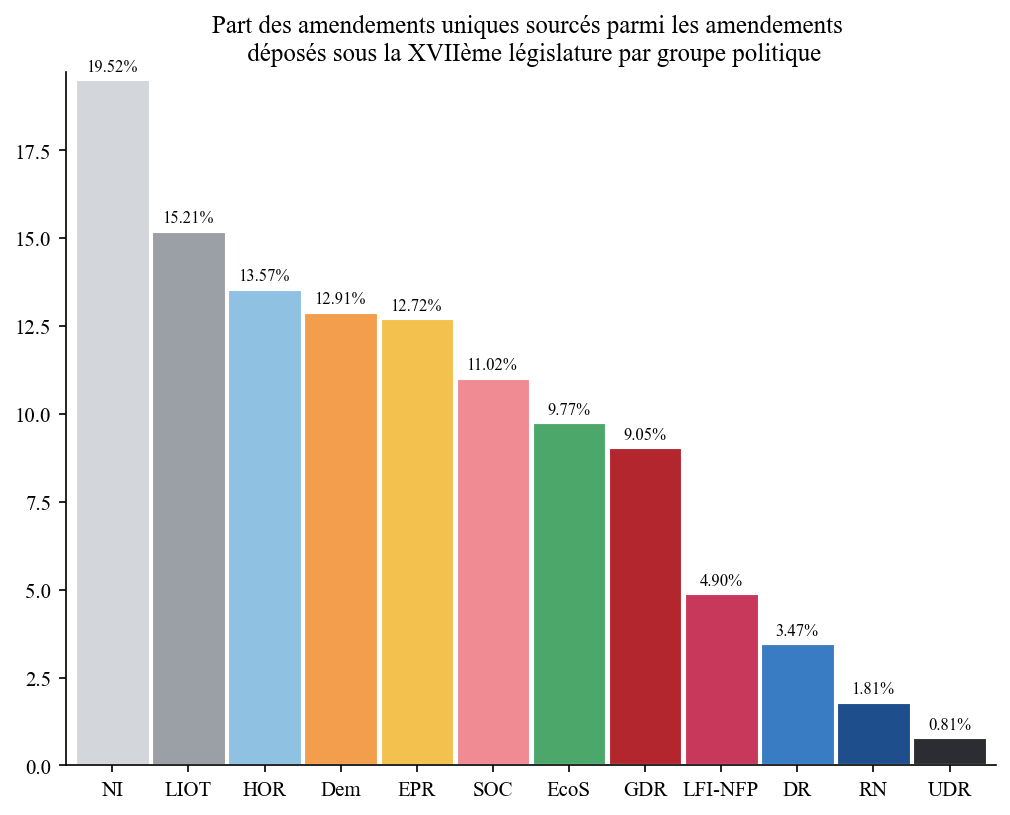

In [13]:
plot_pol_party(pol_party(pred_dataset_uni), "%_source",
               title="Part des amendements uniques sourcés parmi les amendements \n " \
               "déposés sous la XVIIème législature par groupe politique")

### Duplicate dataset

In [14]:
pol_party(pred_dataset_ext).sort(by="%_source", descending=True)

nom_abrev,auteur_groupe_politique_ref,nom,total_source,total_amendements,%_source
str,str,str,u32,u32,f64
null,null,null,1,0,inf
"""NI""","""PO840056""","""Non inscrit""",124,695,17.841727
"""LIOT""","""PO845485""","""Libertés, Indépendants, Outre-…",630,4502,13.993781
"""HOR""","""PO845470""","""Horizons & Indépendants""",405,3448,11.74594
"""EPR""","""PO845407""","""Ensemble pour la République""",1126,10613,10.60963
…,…,…,…,…,…
"""GDR""","""PO845514""","""Gauche Démocrate et Républicai…",364,5694,6.392694
"""LFI-NFP""","""PO845413""","""La France insoumise - Nouveau …",738,18283,4.036537
"""DR""","""PO845425""","""Droite Républicaine""",388,13933,2.784756


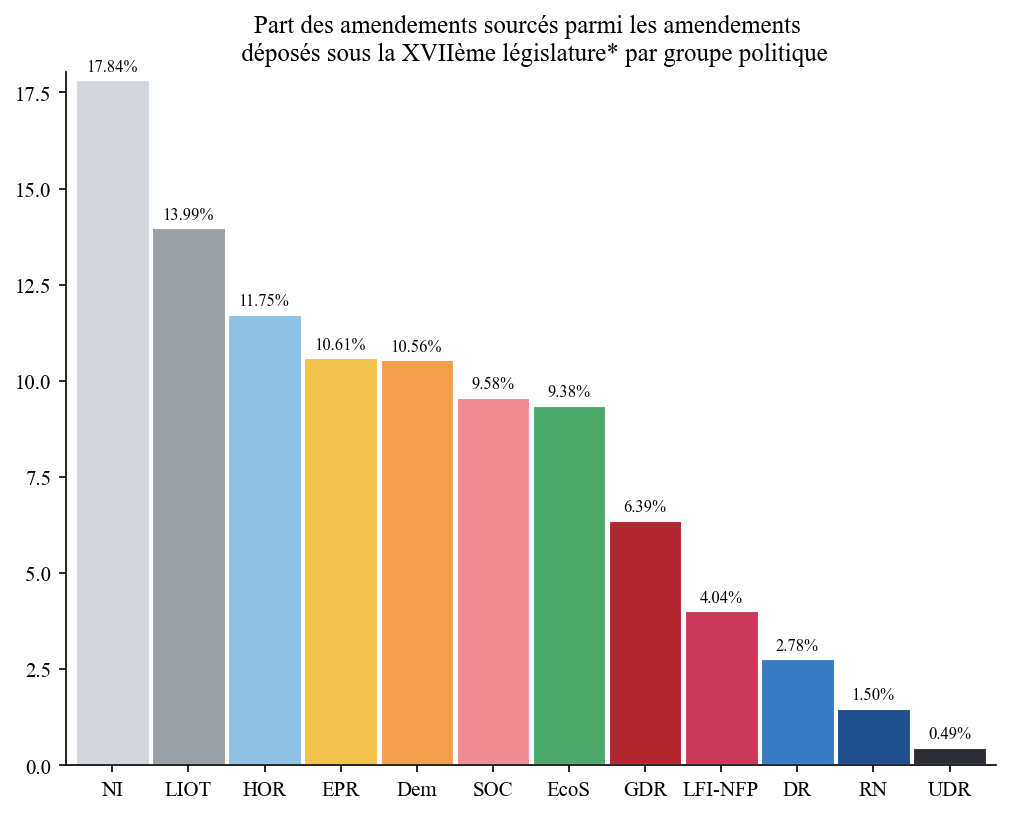

In [15]:
plot_pol_party(pol_party(pred_dataset_ext), "%_source", 
               title="Part des amendements sourcés parmi les amendements \n " \
               "déposés sous la XVIIème législature* par groupe politique")

### Volume total d'amendements déposés par groupe

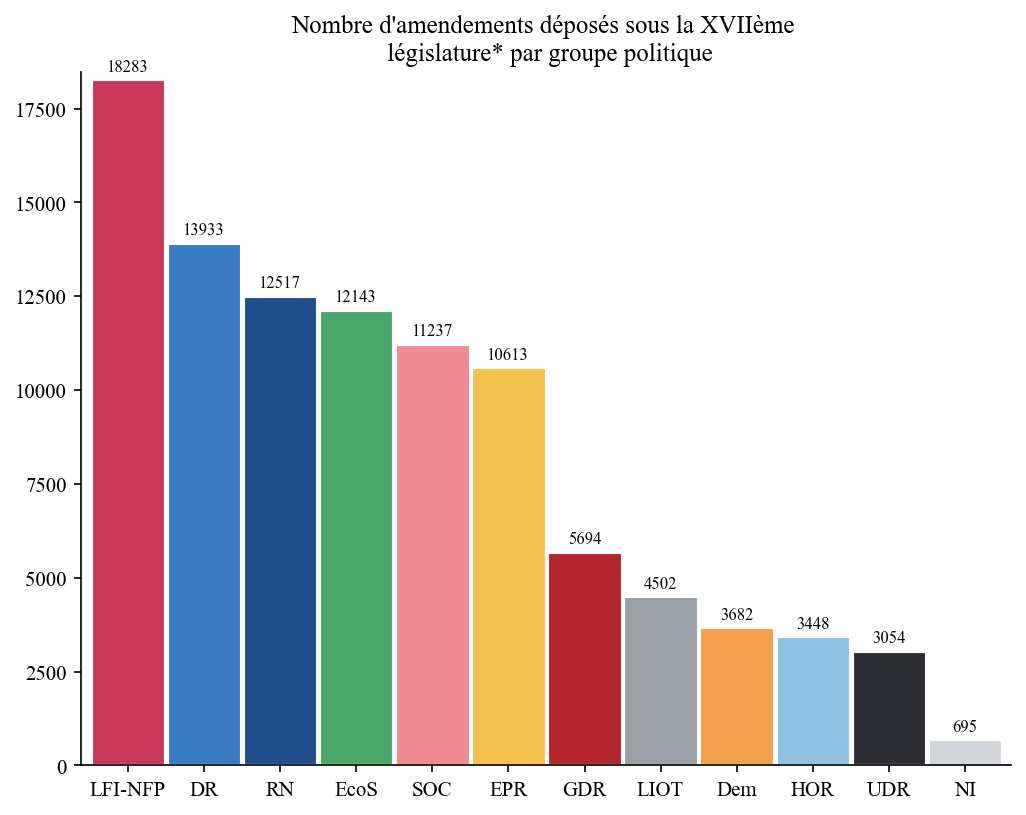

In [16]:
plot_pol_party(pol_party(pred_dataset_ext), "total_amendements", 
               title="Nombre d'amendements déposés sous la XVIIème \n " \
               "législature* par groupe politique")

## RQ3: Le volume d'amendements sourcés est-il stable dans le temps ? 

In [17]:
"""
This function takes a dataframe of predictions as input
and returns a dataframe containing all sourced amendments per filing date (date_depot), the total amount 
of amendments filed that day (total_am_day) and the % of sourced amendments per day (%_source_day).
"""

def source_by_time(pred):

    #extracting the total amount of sourced amendments filed per day
    source = pred.select("uid", "dataset", "expose_sommaire", "prediction", "date_depot")
    source = source.filter(pl.col("prediction") == "source")
    source = source["date_depot"].value_counts()
    source = source.rename({"count": "sourced"})

    #counting the total amount of amendments filed per day
    total = (pred_dataset_ext["date_depot"].value_counts()
            .with_columns(pl.col("count").fill_null(0))
            .group_by("date_depot")
            .agg(pl.col("count").sum())
            .sort("date_depot"))
    total = total.rename({"count": "total_am_day"})

    #concatenating the two
    df = (source.join(total, on="date_depot", how="full", coalesce=True)
            .with_columns(pl.col("sourced", "total_am_day").fill_null(0))
            .sort("date_depot")) 

    #computing %
    df = df.with_columns((pl.col("sourced")/pl.col("total_am_day"))
                        .alias("%_source_day"))

    return df

In [18]:
"""
This function takes the output of source_by_time(), a y_axis ("sourced" if the goal is to plot the volume of 
sourced amendments, or "%_source_day" if the goal is to plot %) and a title as inputs, 
and outputs a bar chart representing the evolution of the y_axis through time (date_depot). 
"""

def time_plot(df_source, y_axis, title="Distribution"):

    df_source = df_source.drop_nulls(subset="date_depot")
    df_source = df_source.with_columns(pl.col("date_depot").str.to_date("%Y-%m-%d"))
    
    title = title
    width=0.98

    fig, axbar=plt.subplots(figsize=(18, 6), dpi=150)
    axbar.bar(df_source["date_depot"], 
              df_source[y_axis], 
              width=width,
            color="#3C6E71")
    
    axbar.set_title(title,  
                family="Times New Roman", 
                fontsize=12)
    
    axbar.margins(x=0.01)
    axbar.set_axisbelow(True)
    axbar.yaxis.grid(color='gray', linestyle='-')
    axbar.spines[['right', 'top']].set_visible(False)

### Unique dataset

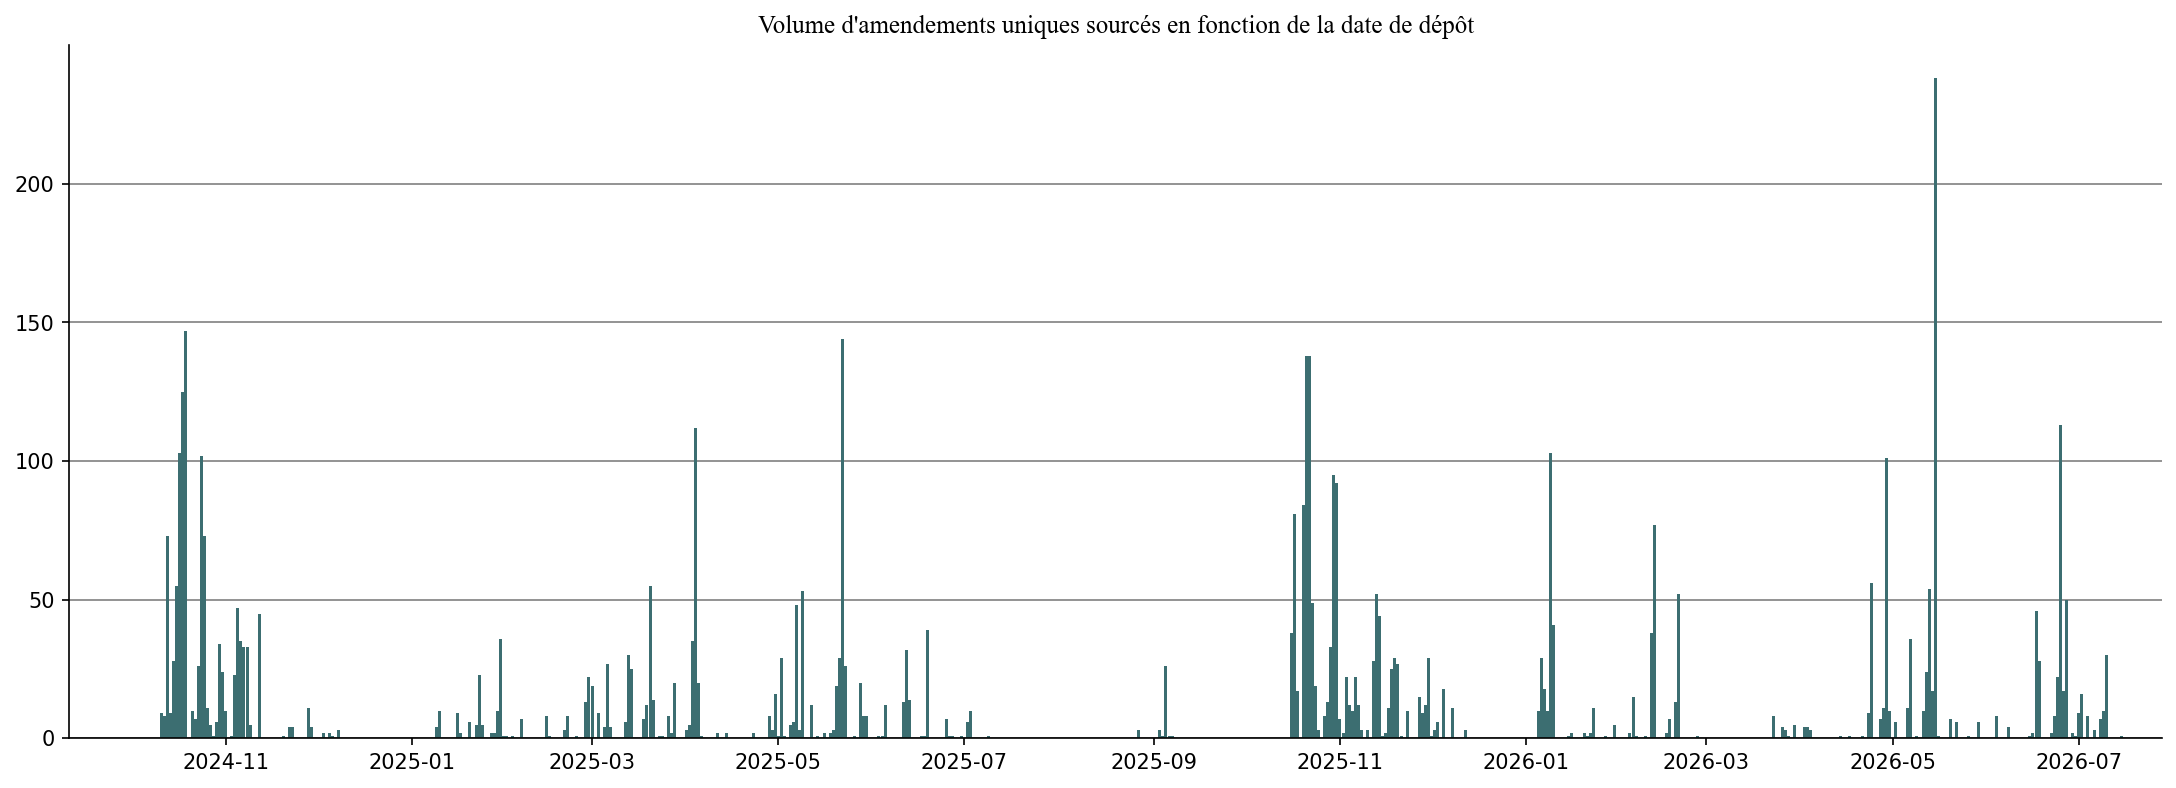

In [19]:
time_plot(source_by_time(pred_dataset_uni), y_axis="sourced", 
          title="Volume d'amendements uniques sourcés en fonction de la date de dépôt")

### Duplicate dataset

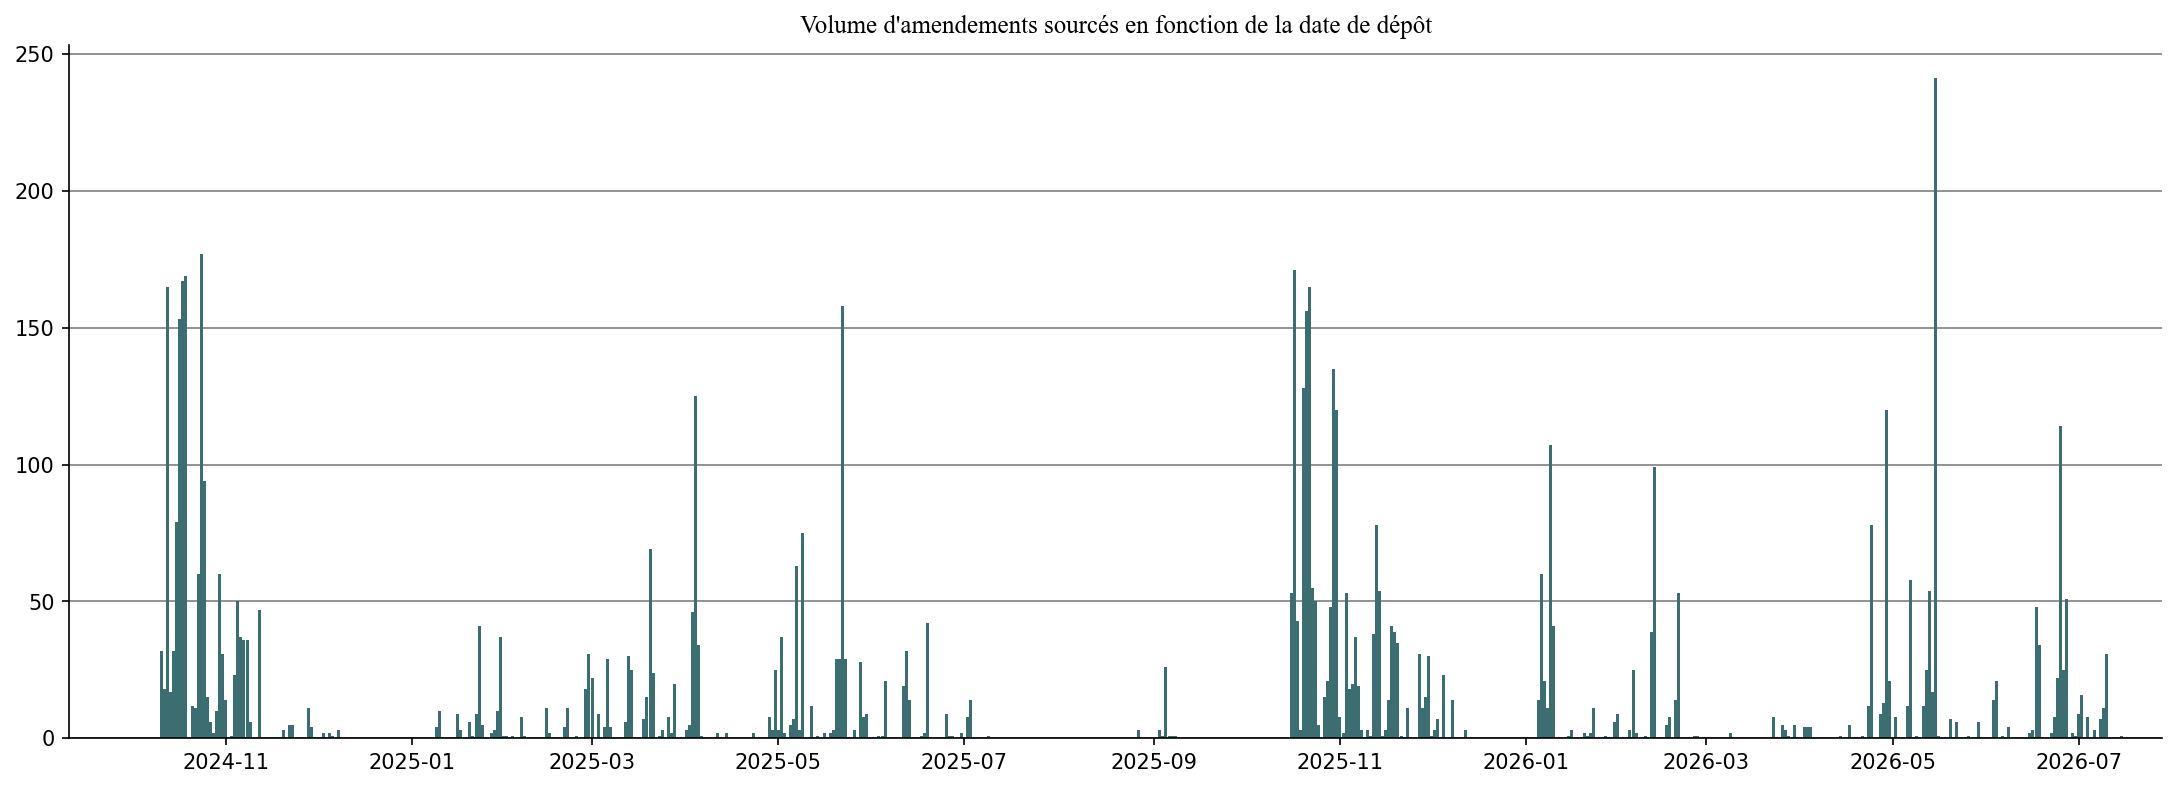

In [20]:
time_plot(source_by_time(pred_dataset_ext), y_axis="sourced", 
          title="Volume d'amendements sourcés en fonction de la date de dépôt")

## Bonus: Les amendements sourcés sont-ils plus susceptibles d'être adoptés que les amendements non-sourcés ? 

In [21]:
"""
This function takes a dataframe of predictions as input
and returns a dataframe containing the total and % of sourced and non-sourced amendments per outcome (sort).
"""

def pred_outcome(pred):

    # total source / non-source per sort (manual + pred)
    df_outcome = (pred.group_by("sort")
                  .agg((pl.col("prediction") == "source").sum().alias("total_source"),
                       (pl.col("prediction") == "non-source").sum().alias("total_non-source"))
                  .sort("sort"))

    df_outcome = df_outcome.with_columns((pl.col("total_source") / pl.col("total_source").sum()*100).alias("%_sort_among_source"))
    df_outcome = df_outcome.with_columns((pl.col("total_non-source") / pl.col("total_non-source").sum()*100).alias("%_sort_among_non-source"))

    return df_outcome

In [22]:
"""
This function takes the output of pred_outcome() as input, 
and outputs a bar chart representing the outcome of amendments depending on their nature (in %). 
"""

def outcome_plot(stats_sort, title): 

    table = stats_sort.fill_null("Null")

    width=0.4
    x = np.arange(len(table["sort"])) 

    fig, axbar=plt.subplots(figsize=(8, 6), dpi=150)
    axbar.bar(x - width/2, table["%_sort_among_non-source"], width=width,
            color='#483C46',
            edgecolor="white",
            linewidth=1.5,
            label="Non-source")
    axbar.bar(x + width/2, table["%_sort_among_source"], width=width,
            color="#3C6E71",
            edgecolor="white",
            linewidth=1.5,
            label="Source")
    axbar.set_xticks(x)
    axbar.set_xticklabels(table["sort"])

    axbar.legend(prop={"family": "Times New Roman", "size": 12}, loc="lower center", bbox_to_anchor=(0.5, 1), ncol=3, edgecolor="none", borderpad=0)
    axbar.margins(0.01, 0.01)
    axbar.set_title(title, family="Times New Roman", fontsize=12, pad=40)

    for tick in axbar.get_xticklabels():
        tick.set_fontname("Times New Roman")
    for tick in axbar.get_yticklabels():
        tick.set_fontname("Times New Roman")

    axbar.set_axisbelow(True)
    axbar.yaxis.grid(color='gray', linestyle='-')
    axbar.spines[['right', 'top']].set_visible(False)

    plt.tight_layout()
    plt.show()

### Unique dataset

In [23]:
pred_outcome(pred_dataset_uni)

sort,total_source,total_non-source,%_sort_among_source,%_sort_among_non-source
str,u32,u32,f64,f64
null,1420,19432,28.013415,32.215388
"""Adopté""",749,9734,14.77609,16.137535
"""Non soutenu""",701,3970,13.829158,6.581674
"""Rejeté""",1196,17528,23.594397,29.058837
"""Retiré""",234,2826,4.616295,4.685091
"""Tombé""",769,6829,15.170645,11.321474


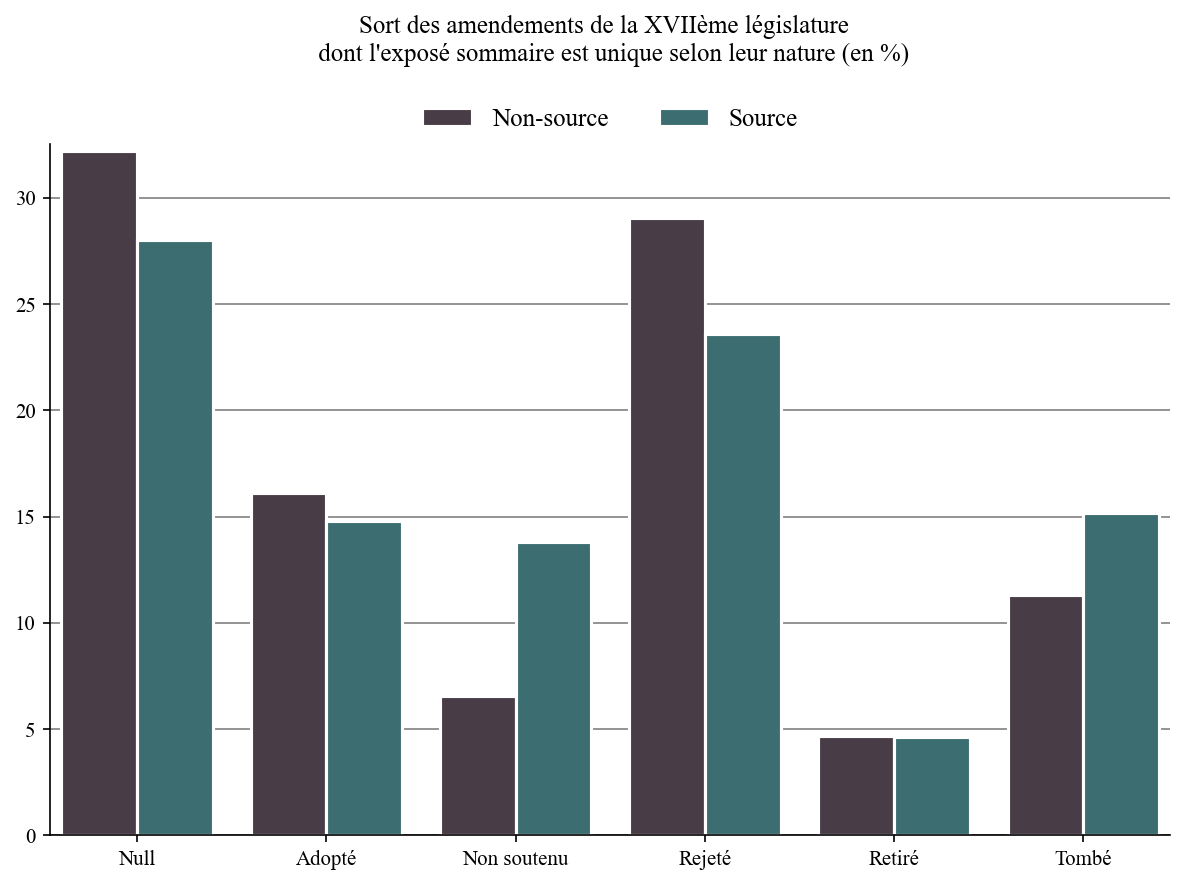

In [24]:
outcome_plot(pred_outcome(pred_dataset_uni), 
             title = "Sort des amendements de la XVIIème législature  \n " \
             "dont l'exposé sommaire est unique selon leur nature (en %)")

### Duplicate dataset

In [25]:
pred_outcome(pred_dataset_ext)

sort,total_source,total_non-source,%_sort_among_source,%_sort_among_non-source
str,u32,u32,f64,f64
null,1635,30349,24.832928,32.443209
"""Adopté""",980,15062,14.884569,16.101342
"""Non soutenu""",921,6477,13.988457,6.92394
"""Rejeté""",1791,27643,27.202309,29.550484
"""Retiré""",292,3875,4.434994,4.142391
"""Tombé""",965,10139,14.656744,10.838634


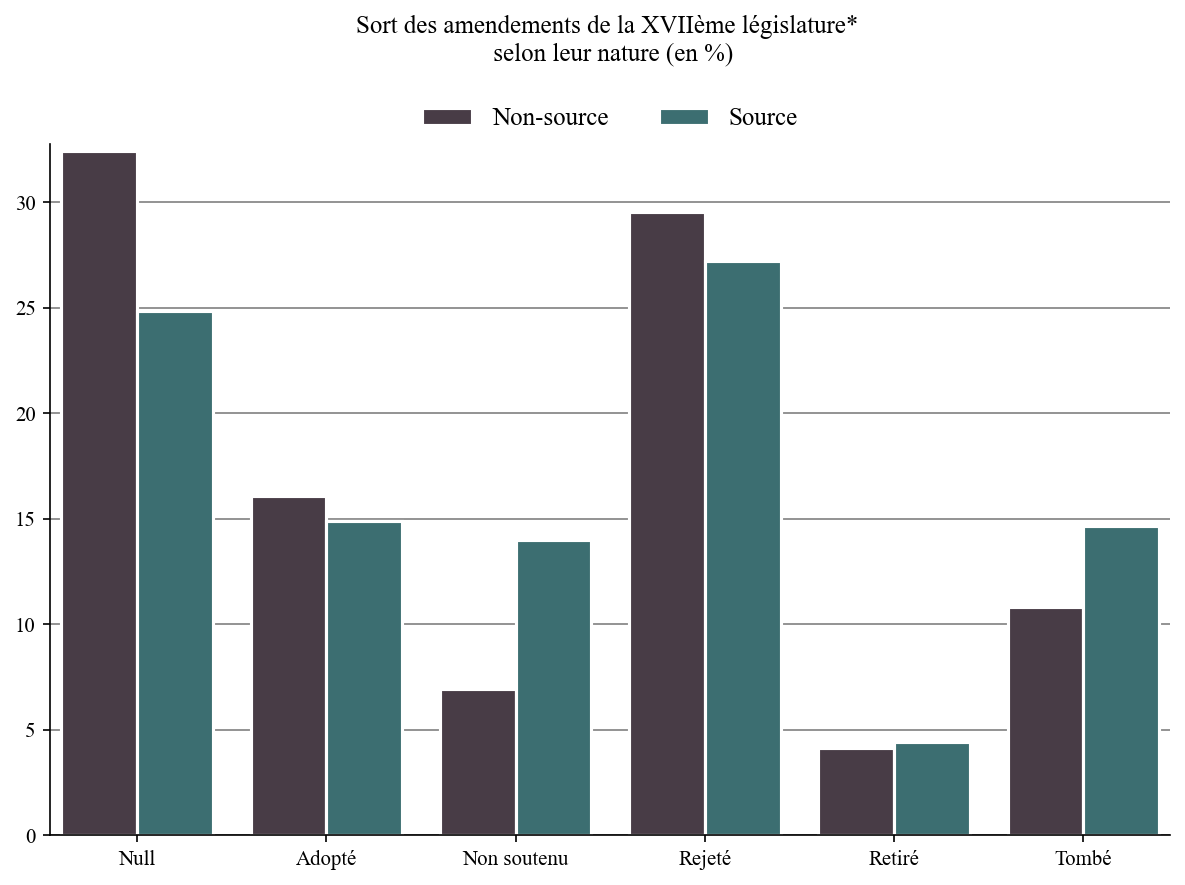

In [26]:
outcome_plot(pred_outcome(pred_dataset_ext), 
             title = "Sort des amendements de la XVIIème législature* \n selon leur nature (en %)")